<a href="https://colab.research.google.com/github/Iucasoa/Sistemas-Inteligentes/blob/main/problema1-regress%C3%A3o-linear/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Importação de Bibliotecas e Configuração
Este bloco inicial carrega as bibliotecas fundamentais do ecossistema Python para o projeto: `pandas` e `numpy` para a manipulação eficiente de dados estruturados e operações matemáticas, `matplotlib` e `seaborn` para a geração de visualizações gráficas e estatísticas padronizadas, e diversos módulos da biblioteca `scikit-learn` para a criação do pipeline de ciência de dados (desde a divisão dos conjuntos de treino e teste, padronização de escala, ajuste do modelo de regressão linear até o cálculo de métricas de validação). Adicionalmente, importa-se a biblioteca `statsmodels` para a análise minuciosa de multicolinearidade por meio do cálculo do VIF (Variance Inflation Factor).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

### 2. Carregamento dos Dados
Esta célula realiza a instalação do pacote especializado `ucimlrepo` para a conexão direta com o repositório oficial de Machine Learning da UCI. Em seguida, o código efetua a requisição programática e o download do conjunto de dados correspondente à planta de Ciclo Combinado de Central Elétrica (ID 294), isolando ordenadamente as variáveis preditoras ambientais e a variável dependente de interesse `PE` (produção horária de energia elétrica líquida) em um único DataFrame unificado da biblioteca `pandas` para as etapas subsequentes.

In [ ]:
!pip install ucimlrepo -q

from ucimlrepo import fetch_ucirepo

ccpp = fetch_ucirepo(id=294)

df = ccpp.data.features.copy()
df["PE"] = ccpp.data.targets

### 3. Análise Exploratória Inicial e Tratamento de Nulos
Este bloco executa um diagnóstico estrutural inicial sobre o conjunto de dados carregado. Primeiramente, verifica-se a volumetria da base através da propriedade `shape`. Posteriormente, inspecionam-se as primeiras linhas do DataFrame para compreender sua distribuição visual e geram-se as estatísticas descritivas básicas (como médias, desvios padrão, valores mínimos, máximos e quartis) de forma transposta para facilitar a leitura. Por fim, executa-se uma verificação minuciosa de dados ausentes seguida da limpeza preventiva por meio do método `dropna`, garantindo a qualidade metodológica para a modelagem.

In [ ]:
print("Dimensão:", df.shape)
display(df.head())
display(df.describe() .T)

print(df.isnull() .sum())
df = df.dropna()

Dimensão: (9568, 5)


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


,count,mean,std,min,25%,50%,75%,max
AT,9568.0,19.651231,7.452473,1.81,13.5100,20.345,25.72,37.11
V,9568.0,54.305804,12.707893,25.36,41.7400,52.080,66.54,81.56
AP,9568.0,1013.259078,5.938784,992.89,1009.1000,1012.940,1017.26,1033.30
RH,9568.0,73.308978,14.600269,25.56,63.3275,74.975,84.83,100.16
PE,9568.0,454.365009,17.066995,420.26,439.7500,451.550,468.43,495.76


AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64


### 4. Seleção de Variáveis
Esta etapa consiste na partição lógica e estruturação das variáveis do projeto. Isola-se o conjunto de características preditoras de interesse, composto pelas variáveis físicas ambientais `AT` (Temperatura Ambiente), `V` (Vácuo), `AP` (Pressão Atmosférica) e `RH` (Umidade Relativa), as quais são atribuídas à matriz de atributos `X`. De forma concomitante, define-se o vetor de resposta `y` contendo exclusivamente o alvo contínuo `PE` (produção de energia útil), que será o objeto de predição do modelo de regressão linear.

In [ ]:
features_names = ["AT", "V", "AP", "RH"]

X = df[features_names]
y = df["PE"]

### 5. Correlação de Pearson
Este bloco realiza o cálculo quantitativo da matriz de correlação linear de Pearson para mensurar a força e a direção da associação linear entre as variáveis. O código extrai especificamente os coeficientes associados à variável resposta `PE` frente aos demais preditores, apresentando-os ordenados em ordem decrescente pelo seu valor absoluto. Esse procedimento permite identificar imediatamente quais fatores ambientais possuem maior relevância estatística individual e impacto direto sobre a geração de energia na usina.

In [ ]:
corr_matrix = df.corr() #correlação de pearson entre todos os pares de colunas, resultando em uma 5x5
corr_pe = corr_matrix["PE"].drop("PE")
print(corr_pe.sort_values(key=abs, ascending=False))

AT   -0.948128
V    -0.869780
AP    0.518429
RH    0.389794
Name: PE, dtype: float64


### 6. Matriz de Correlação Gráfica e Cálculo do VIF
Este trecho executa uma análise estatística avançada voltada à detecção de redundâncias e interdependências entre as variáveis explicativas através de ferramentas visuais e numéricas:
* **Análise das Associações Lineares:** O mapa de calor (heatmap) gerado pela biblioteca `seaborn` ilustra visualmente a intensidade das correlações. Destaca-se a forte correlação negativa da temperatura ambiente (`AT`, $r = -0.948$) e do vácuo (`V`, $r = -0.870$) com o volume de energia gerado (`PE`), indicando que climas frios e maior eficiência no vácuo favorecem a produção. Por outro lado, a pressão atmosférica (`AP`) e a umidade (`RH`) exibem associações positivas de intensidade moderada a fraca.
* **Investigação de Multicolinearidade (VIF):** A observação de uma elevada correlação mútua entre `AT` e `V` ($r = 0.844$) motivou o cálculo do Fator de Inflação de Variância (VIF). Os resultados revelam um VIF de $5.98$ para a variável `AT` e de $3.94$ para `V`. Embora os índices não ultrapassem os limites críticos severos (geralmente fixados em 10), o comportamento de `AT` indica uma multicolinearidade moderada que requer atenção analítica, pois a colinearidade pode inflar a variância dos coeficientes estimados na regressão múltipla.

       AT      V     AP     RH
AT  1.000  0.844 -0.508 -0.543
V   0.844  1.000 -0.414 -0.312
AP -0.508 -0.414  1.000  0.100
RH -0.543 -0.312  0.100  1.000


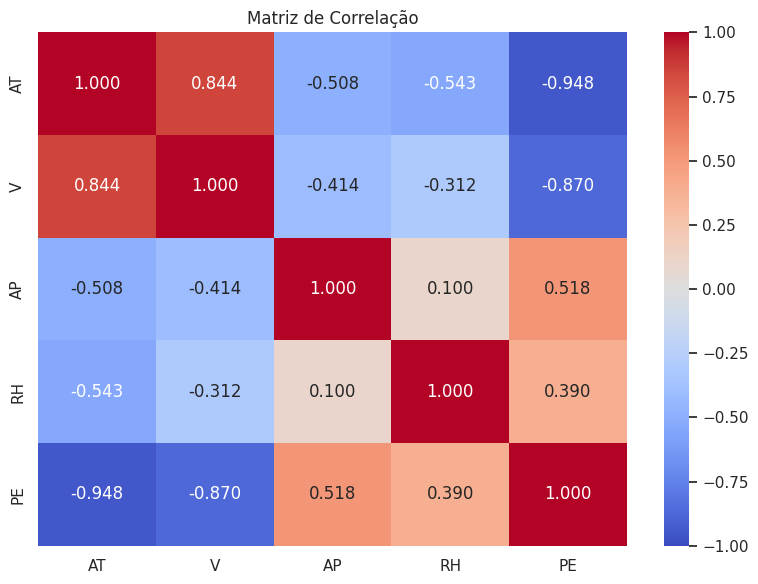

AT: 5.98
V: 3.94
AP: 1.45
RH: 1.71


In [ ]:
print(X.corr().round(3))
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".3f", vmin=-1, vmax=1)

plt.title("Matriz de Correlação")
plt.tight_layout()
plt.savefig("matriz_correlacao.png", dpi=300)
plt.show()

Xc = add_constant(X)

for i, col in enumerate(Xc.columns):
  if col != "const":
    print(f"{col}: {variance_inflation_factor(Xc.values, i):.2f}")

### 7. Divisão dos Dados, Escalonamento e Treinamento do Modelo
Este bloco implementa a divisão dos dados em conjuntos de treinamento (80%) e teste (20%) para garantir uma validação externa robusta. Em seguida, aplica-se a padronização das escalas das variáveis explicativas por meio do `StandardScaler` (z-score), permitindo a comparação direta do peso de cada parâmetro no modelo:
* **Pesos e Importância Relativa:** A análise dos coeficientes padronizados aponta a temperatura ambiente (`AT`, coeficiente de $-14.76$) como a variável preditora de maior impacto relativo sobre a produção. Seguem-se os efeitos negativos de menor escala do vácuo (`V`, $-2.95$) e da umidade relativa (`RH`, $-2.31$), enquanto a pressão atmosférica (`AP`, $+0.37$) demonstra peso marginal no ajuste do modelo.
* **Inversão de Sinal:** Nota-se o fenômeno estatístico em que o coeficiente da variável `RH` assumiu sinal negativo ($-0.158$) na regressão múltipla, apesar de sua correlação de Pearson simples com `PE` ter sido positiva ($+0.390$). Esse ajuste ocorre pela presença conjunta de variáveis colineares, isolando o efeito líquido da umidade sob a premissa de que as demais condições ambientais permanecem constantes (efeito *ceteris paribus*).
* **Equação Matemática na Escala Original:** A transformação inversa dos parâmetros resulta no seguinte modelo matemático de predição:
  $$\text{PE} = 454.5691 - 1.9859 \times \text{AT} - 0.2321 \times \text{V} + 0.0622 \times \text{AP} - 0.1581 \times \text{RH}$$
  A equação indica que a cada elevação de $1^\circ\text{C}$ na temperatura ambiente, estima-se uma redução média de aproximadamente $1.99\text{ MW}$ na produção líquida de energia elétrica da central.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_s, y_train)

print("=== Coeficientes Padronizados (Escalonados) ===")
for var, coef in zip(features_names, model.coef_):
    print(f"{var}: {coef:.4f}")
print(f"Intercept: {model.intercept_:.4f}\n")

coef_orig = model.coef_ / scaler.scale_
intercept_orig = model.intercept_ - np.sum(model.coef_ * scaler.mean_ / scaler.scale_)

print("=== Coeficientes Originais ===")
for var, coef in zip(features_names, coef_orig):
    print(f"{var}: {coef:.4f}")
print(f"Intercept (original): {intercept_orig:.4f}\n")

print("=== Equação do Modelo ===")
print(f"PE = {intercept_orig:.4f} + ({coef_orig[0]:.4f} * AT) + ({coef_orig[1]:.4f} * V) + ({coef_orig[2]:.4f} * AP) + ({coef_orig[3]:.4f} * RH)")

print("Intercepto (escala z-score):", round(model.intercept_, 4))

print("\nEquação na escala original:")
print("Intercepto:", round(intercept_orig, 4))
for var, c in zip(features_names, coef_orig):
    print(f"{var}: {c:+.4f}")

=== Coeficientes Padronizados (Escalonados) ===
AT: -14.7639
V: -2.9496
AP: 0.3698
RH: -2.3122
Intercept: 454.4310

=== Coeficientes Originais ===
AT: -1.9859
V: -0.2321
AP: 0.0622
RH: -0.1581
Intercept (original): 454.5691

=== Equação do Modelo ===
PE = 454.5691 + (-1.9859 * AT) + (-0.2321 * V) + (0.0622 * AP) + (-0.1581 * RH)
Intercepto (escala z-score): 454.431

Equação na escala original:
Intercepto: 454.5691
AT: -1.9859
V: -0.2321
AP: +0.0622
RH: -0.1581


### 8. Avaliação do Modelo
O bloco realiza a predição da produção de energia no conjunto de teste independente para avaliar o poder de generalização do algoritmo frente a dados inéditos. O desempenho é quantificado através de três métricas de erro consagradas:
* **Coeficiente de Determinação ($R^2 = 0.9301$):** Indica que a especificação linear das quatro variáveis físicas explicativas consegue modelar e capturar com sucesso cerca de $93.01\%$ da variabilidade associada à produção de energia elétrica (`PE`).
* **Raiz do Erro Quadrático Médio ($RMSE = 4.50\text{ MW}$):** Representa o desvio padrão dos resíduos do modelo, indicando um erro médio nas predições de aproximadamente $4.50\text{ MW}$. Este valor é de extrema relevância prática, pois corresponde a meros $5.96\%$ de erro quando comparado à amplitude total da faixa de operação observada no dataset.
* **Erro Absoluto Médio ($MAE = 3.60\text{ MW}$):** Demonstra a magnitude média das distâncias absolutas entre os valores preditos e reais. A proximidade entre os valores de MAE e RMSE atesta a ausência de perturbações excessivas causadas por valores discrepantes (outliers) severos no modelo.

In [ ]:
y_pred = model.predict(X_test_s)

r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

print(f"R²: {r2:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"RMSE relativo à faixa: {100*rmse/(y.max()-y.min()):.2f}%")


R²: 0.9301
RMSE: 4.5026
MAE: 3.5959
RMSE relativo à faixa: 5.96%


### 9. Análise Gráfica dos Resíduos
Este bloco gera uma painel de diagnósticos visuais fundamental para ratificar a adequação e validar os pressupostos teóricos clássicos da regressão linear múltipla:
* **Valores Reais vs. Previsões:** O gráfico de dispersão inicial evidencia um alinhamento bastante estreito e linear dos pontos observados em torno da bissetriz vermelha (linha de predição ideal), ratificando a excelente aderência e acurácia do modelo ajustado.
* **Distribuição dos Erros (Normalidade):** O histograma acompanhado de curva de densidade suavizada (KDE) revela uma distribuição simétrica dos erros em torno de zero. O comportamento assemelha-se satisfatoriamente a uma curva de distribuição normal, confirmando a robustez para estimativas e testes de significância.
* **Resíduos vs. Valores Previstos (Homocedasticidade):** A dispersão dos erros sobre a reta de referência nula mostra-se amplamente dispersa de forma homogênea. Embora seja possível identificar uma sutil curvatura na distribuição dos resíduos que aponta para efeitos não lineares marginais não capturados pelo ajuste linear rígido, o espalhamento não indica a presença de heterocedasticidade severa (formato de funil), validando a confiabilidade das estimativas.

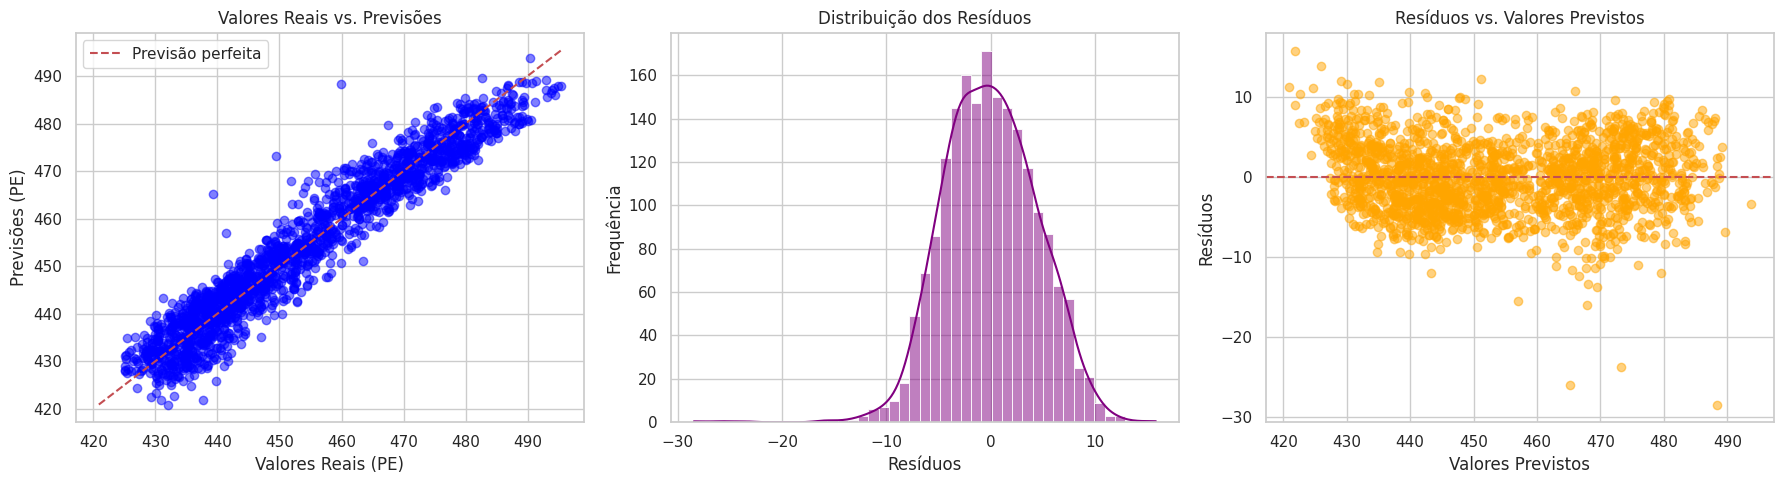

In [ ]:
residuals = y_test - y_pred

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# 1. Valores Reais vs. Previstos
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax[0].scatter(y_test, y_pred, alpha=0.5, color="blue")
ax[0].plot(lims, lims, "r--", label="Previsão perfeita")
ax[0].set_xlabel("Valores Reais (PE)")
ax[0].set_ylabel("Previsões (PE)")
ax[0].set_title("Valores Reais vs. Previsões")
ax[0].legend()

# 2. Distribuição dos Resíduos
sns.histplot(residuals, kde=True, ax=ax[1], color="purple")
ax[1].set_xlabel("Resíduos")
ax[1].set_ylabel("Frequência")
ax[1].set_title("Distribuição dos Resíduos")

# 3. Resíduos vs. Valores Previstos
ax[2].scatter(y_pred, residuals, alpha=0.5, color="orange")
ax[2].axhline(y=0, color="r", linestyle="--")
ax[2].set_xlabel("Valores Previstos")
ax[2].set_ylabel("Resíduos")
ax[2].set_title("Resíduos vs. Valores Previstos")

plt.tight_layout()
plt.savefig("diagnostico_modelo.png", dpi=300)
plt.show()

In [ ]:
from google.colab import files

files.download("matriz_correlacao.png")
files.download("diagnostico_modelo.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>